# This loads generated data from **data_generation** without having to run the entire solver again

In [ ]:
import sys
from pathlib import Path

# Path stuff for troubleshooting
project_path = Path.cwd().parent
sys.path.insert(0, str(project_path / "src"))

print(
    "Neural network file found:",
    (project_path / "src" / "wing_surrogate" / "neural_network.py").is_file()
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torch import nn
from sklearn.preprocessing import StandardScaler

from wing_surrogate.neural_network import build_model as build_nn_model
from wing_surrogate.polynomial_regression import build_model

df = pd.read_csv(project_path / "data" / "wing_data_trial.csv")

print("Number of samples:", len(df))
df.head()

Neural network file found: True
Number of samples: 9


,geometry_id,aspect_ratio,area_m2,taper_ratio,sweep_deg,airfoil,velocity,alpha_deg,CL,CD_profile,max_lift_error,runtime_s
0,wing_0fea48fba59253a479f3,6.0,1.0,0.5,0.0,naca0012,100.0,2.0,0.158375,0.005250,7.244205e-15,6.691710
1,wing_0fea48fba59253a479f3,6.0,1.0,0.5,0.0,naca0012,100.0,5.0,0.395948,0.005958,8.104628e-15,6.453341
2,wing_0fea48fba59253a479f3,6.0,1.0,0.5,0.0,naca0012,100.0,8.0,0.626846,0.007262,1.270650e-13,9.389478
3,wing_126480edad821890d75a,8.0,1.0,0.5,0.0,naca0012,100.0,2.0,0.172767,0.005278,9.547918e-15,15.957298
4,wing_126480edad821890d75a,8.0,1.0,0.5,0.0,naca0012,100.0,5.0,0.430345,0.006218,5.051515e-15,15.011072


In [15]:
input_features = ["aspect_ratio", "alpha_deg"]
output_features = ["CL", "CD_profile"]

training_data = df[df["aspect_ratio"] != 8.0]
testing_data = df[df["aspect_ratio"] == 8.0]

X_train = training_data[input_features]
Y_train = training_data[output_features]

X_test = testing_data[input_features]
Y_test = testing_data[output_features]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 6
Testing samples: 3


# Polynomial Regression

In [16]:
# Start with degree 1 because our trial dataset is very small
model = build_model(degree=1)

model.fit(X_train, Y_train)

Y_train_pred = model.predict(X_train)
Y_test_pred = model.predict(X_test)

# Errors
for i in range(len(output_features)):

    training_MSE = np.mean(
        (Y_train_pred[:, i] - Y_train.iloc[:, i].to_numpy()) ** 2
    )

    testing_MSE = np.mean(
        (Y_test_pred[:, i] - Y_test.iloc[:, i].to_numpy()) ** 2
    )

    print("Output:", output_features[i])
    print("Training MSE:", training_MSE)
    print("Testing MSE:", testing_MSE)
    print()

Output: CL
Training MSE: 0.0002156098291108099
Testing MSE: 4.018117245581935e-05

Output: CD_profile
Training MSE: 6.498197350085577e-08
Testing MSE: 2.6079450960306345e-08



# Polynomial Regression Plots

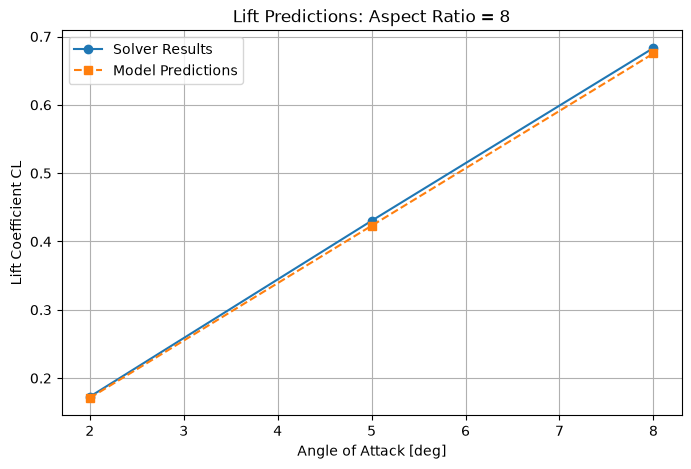

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    X_test["alpha_deg"],
    Y_test["CL"],
    "o-",
    label="Solver Results"
)

plt.plot(
    X_test["alpha_deg"],
    Y_test_pred[:, 0],
    "s--",
    label="Model Predictions"
)

plt.xlabel("Angle of Attack [deg]")
plt.ylabel("Lift Coefficient CL")
plt.title("Lift Predictions: Aspect Ratio = 8")
plt.legend()
plt.grid()
plt.show()

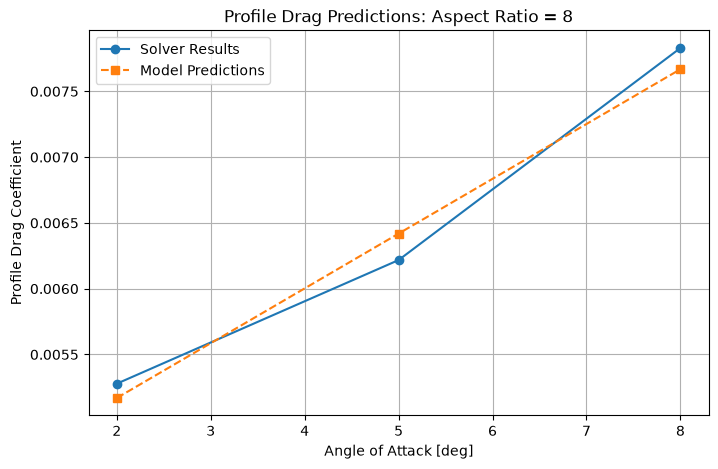

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    X_test["alpha_deg"],
    Y_test["CD_profile"],
    "o-",
    label="Solver Results"
)

plt.plot(
    X_test["alpha_deg"],
    Y_test_pred[:, 1],
    "s--",
    label="Model Predictions"
)

plt.xlabel("Angle of Attack [deg]")
plt.ylabel("Profile Drag Coefficient")
plt.title("Profile Drag Predictions: Aspect Ratio = 8")
plt.legend()
plt.grid()
plt.show()

# Neural Network Test

In [ ]:
torch.manual_seed(10)

X_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(X_train)
X_test_scaled = X_scaler.transform(X_test)

Y_scaler = StandardScaler()
Y_train_scaled = Y_scaler.fit_transform(Y_train)

Scaled training inputs:
[[-1.         -1.22474487]
 [-1.          0.        ]
 [-1.          1.22474487]
 [ 1.         -1.22474487]
 [ 1.          0.        ]
 [ 1.          1.22474487]]
Scaled training outputs:
[[-1.2695609  -1.07828264]
 [-0.13008195 -0.42523223]
 [ 0.97738439  0.77794946]
 [-1.15449642 -1.02095064]
 [ 0.14027498  0.01192785]
 [ 1.4364799   1.73458821]]


In [21]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

Y_train_tensor = torch.tensor(Y_train_scaled, dtype=torch.float32)

In [22]:
torch.manual_seed(10)

nn_model = build_nn_model(input_size=2, output_size=2)

loss_fun = nn.MSELoss()
optimizer = torch.optim.Adam(nn_model.parameters(), lr=0.01)

Epoch = 1000
Train_Losses = []

for epoch in range(Epoch):

    nn_model.train()

    Y_pred = nn_model(X_train_tensor)

    loss = loss_fun(Y_pred, Y_train_tensor)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    Train_Losses.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch + 1}, Training Loss: {loss.item():.6f}")

Epoch 100, Training Loss: 0.000904
Epoch 200, Training Loss: 0.000089
Epoch 300, Training Loss: 0.000042
Epoch 400, Training Loss: 0.000029
Epoch 500, Training Loss: 0.000023
Epoch 600, Training Loss: 0.000019
Epoch 700, Training Loss: 0.000016
Epoch 800, Training Loss: 0.000014
Epoch 900, Training Loss: 0.000012
Epoch 1000, Training Loss: 0.000010


In [23]:
nn_model.eval()

with torch.no_grad():
    Y_train_nn_scaled = nn_model(X_train_tensor).numpy()
    Y_test_nn_scaled = nn_model(X_test_tensor).numpy()

Y_train_nn_pred = Y_scaler.inverse_transform(Y_train_nn_scaled)
Y_test_nn_pred = Y_scaler.inverse_transform(Y_test_nn_scaled)

In [24]:
for i in range(len(output_features)):

    training_MSE = np.mean(
        (Y_train_nn_pred[:, i] - Y_train.iloc[:, i].to_numpy()) ** 2
    )

    testing_MSE = np.mean(
        (Y_test_nn_pred[:, i] - Y_test.iloc[:, i].to_numpy()) ** 2
    )

    print("Output:", output_features[i])
    print("Neural Network Training MSE:", training_MSE)
    print("Neural Network Testing MSE:", testing_MSE)
    print()

Output: CL
Neural Network Training MSE: 6.089080068069511e-07
Neural Network Testing MSE: 0.00021940297949832725

Output: CD_profile
Neural Network Training MSE: 6.012832551540814e-12
Neural Network Testing MSE: 1.823860101532668e-08



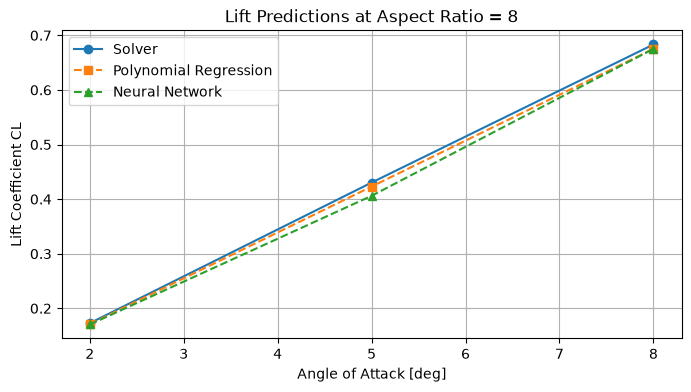

In [25]:
plt.figure(figsize=(8, 4))

plt.plot(
    X_test["alpha_deg"], Y_test["CL"],
    "o-", label="Solver"
)

plt.plot(
    X_test["alpha_deg"], Y_test_pred[:, 0],
    "s--", label="Polynomial Regression"
)

plt.plot(
    X_test["alpha_deg"], Y_test_nn_pred[:, 0],
    "^--", label="Neural Network"
)

plt.xlabel("Angle of Attack [deg]")
plt.ylabel("Lift Coefficient CL")
plt.title("Lift Predictions at Aspect Ratio = 8")
plt.legend()
plt.grid()
plt.show()

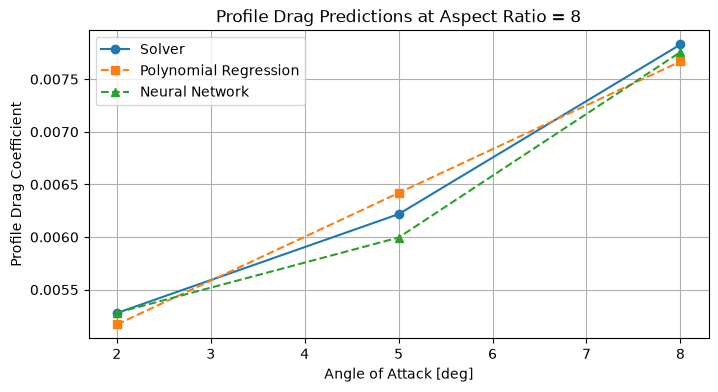

In [26]:
plt.figure(figsize=(8, 4))

plt.plot(
    X_test["alpha_deg"], Y_test["CD_profile"],
    "o-", label="Solver"
)

plt.plot(
    X_test["alpha_deg"], Y_test_pred[:, 1],
    "s--", label="Polynomial Regression"
)

plt.plot(
    X_test["alpha_deg"], Y_test_nn_pred[:, 1],
    "^--", label="Neural Network"
)

plt.xlabel("Angle of Attack [deg]")
plt.ylabel("Profile Drag Coefficient")
plt.title("Profile Drag Predictions at Aspect Ratio = 8")
plt.legend()
plt.grid()
plt.show()